# 05. Retention policy analysis

**Why this notebook exists.** Notebook 04 answers "is the model good, and is one cutoff profitable?"
This notebook answers the follow-up a retention team would actually ask: **given a budget and a cost
per contact, which customers should we contact, and how do the alternatives compare?** It is also
the prototype for the dashboard's Retention Simulator. Every function here is later copied into
`churn_core/economics.py`, and the numbers below are what that code must reproduce.

**Inputs (no model is loaded or retrained).**
`reports/test_predictions.csv` (1,409 held-out customers) and `reports/scores.csv`
(all 7,043 customers; training rows are out-of-fold).

**Assumptions (not measured).** Offer success rate r = 0.5, discount d = 20%, horizon M = 12 months.
The data contains no offers, so r cannot be estimated from it. Savings are in the data's currency
units, before contact costs unless stated.

**What is in here.**
1. Economics functions and a self-test against notebook 04 (all numbers must match).
2. The effect of a per-contact cost: the cutoff rule vs ranking customers by expected value.
3. Baselines at the same contact budget, and a value-versus-budget curve.
4. Sensitivity to r.
5. A pooled backtest on all 7,043 customers, clearly labelled because training rows are out-of-fold.

**Limitation.** The model predicts who will churn, not who would respond to an offer, so a single
uniform r is assumed for everyone.

In [1]:
# Reads only files from reports/. Nothing is retrained.
 
import numpy as np
import pandas as pd
 
r, d, M = 0.5, 0.2, 12                     # offer success rate, discount, months (assumptions)
CUTOFF = d / (d + r * (1 - d))             # 0.3333...
 
tp = pd.read_csv("../reports/test_predictions.csv")     # 1,409 held-out customers
p = tp.p_cal.to_numpy()                    # calibrated churn probability
y = tp.actual_churn.to_numpy()             # real outcome
B = tp.monthly_charges.to_numpy()          # monthly bill

n = len(tp)
print(n, "test customers | cutoff", round(CUTOFF, 4))

1409 test customers | cutoff 0.3333


In [3]:
# Contacting customer i (everyone contacted is offered the discount):
#   churner who accepts   (prob r)      -> keeps paying (1-d)*B for M months
#   loyal customer        (any r)       -> takes the discount, costs d*B for M months
#   minus a cost c per contact
 
def ev_per_customer(p, B, r=r, d=d, M=M, c=0.0):
    """EXPECTED net value of contacting each customer, using calibrated probabilities."""
    return M * B * (p * r * (1 - d) - (1 - p) * d) - c
 
def realized_value(flag, y, B, r=r, d=d, M=M, c=0.0):
    """Value of a flagged set using REAL churn outcomes (expected over whether a churner accepts)."""
    flag = np.asarray(flag, bool)
    hit = flag & (y == 1)                  # flagged churners
    false_alarm = flag & (y == 0)          # flagged loyal customers
    return M * (r * (1 - d) * B[hit].sum() - d * B[false_alarm].sum()) - c * flag.sum()
 
def expected_value(flag, p, B, r=r, d=d, M=M, c=0.0):
    """Value of a flagged set according to the model's own probabilities."""
    return ev_per_customer(p, B, r, d, M, c)[np.asarray(flag, bool)].sum()

In [4]:
def policy_threshold(p, cutoff=CUTOFF):
    """Plain rule: contact everyone whose probability is above the cutoff."""
    return p >= cutoff
 
def policy_ranked(p, B, r=r, d=d, M=M, c=0.0, fixed_cost=0.0, capacity=None):
    """Contact customers with POSITIVE expected value, best first, within a contact capacity.
    With a per-contact cost c the break-even probability depends on each customer's bill,
    so one probability cutoff is no longer optimal. fixed_cost is a campaign-level cost."""
    ev = ev_per_customer(p, B, r, d, M, c)
    n_positive = int((ev > 0).sum())
    k = n_positive if capacity is None else min(int(capacity), n_positive)
    flag = np.zeros(len(p), bool)
    flag[np.argsort(-ev)[:k]] = True
    if flag.any() and ev[flag].sum() <= fixed_cost:      # not worth running the campaign at all
        flag[:] = False
    return flag

In [5]:
flag_model = policy_threshold(p)
flag_all = np.ones(n, bool)
flag_naive = ((tp.contract == "Month-to-month") & (tp.tenure < 12)).to_numpy()
k = int(flag_naive.sum())
flag_topk = np.zeros(n, bool); flag_topk[np.argsort(-p)[:k]] = True
random_expected = realized_value(flag_all, y, B) / n * len(flag_model[flag_model])   # same flag count
 
checks = {
    "Model at cutoff, real outcomes (expect 60,674)": realized_value(flag_model, y, B),
    "Model at cutoff, expected      (expect 67,009)": expected_value(flag_model, p, B),
    "Offer everyone                 (expect -17,132)": realized_value(flag_all, y, B),
    "Random, same flags             (expect  -6,031)": random_expected,
    f"Naive rule, {k} flags           (expect  43,079)": realized_value(flag_naive, y, B),
    f"Model top {k}                   (expect  62,382)": realized_value(flag_topk, y, B),
}
for name, val in checks.items():
    print(f"{name:52s} {val:>10,.0f}")
 
# With no contact cost, the ranked policy must pick exactly the same customers as the cutoff rule
assert (policy_ranked(p, B) == flag_model).all()
print("ranked policy == threshold policy when c = 0: OK, flagged", int(flag_model.sum()))
 

Model at cutoff, real outcomes (expect 60,674)           60,674
Model at cutoff, expected      (expect 67,009)           67,009
Offer everyone                 (expect -17,132)         -17,132
Random, same flags             (expect  -6,031)          -6,031
Naive rule, 385 flags           (expect  43,079)         43,079
Model top 385                   (expect  62,382)         62,382
ranked policy == threshold policy when c = 0: OK, flagged 496


In [6]:
import matplotlib.pyplot as plt
 
# Value each customer WOULD add if contacted, using real outcomes (minus contact cost c).
def realized_per_customer(y, B, r=r, d=d, M=M, c=0.0):
    return M * B * np.where(y == 1, r * (1 - d), -d) - c
 
rows = []
for c in [0, 5, 10, 20, 40]:                       # contact cost per customer, in the data's currency units
    f_thr = policy_threshold(p)                    # ignores c, still pays it for every contact
    f_rank = policy_ranked(p, B, c=c)              # only contacts customers whose expected value beats c
    rows.append({"contact cost c": c,
                 "threshold: flagged": int(f_thr.sum()), "threshold: value": round(realized_value(f_thr, y, B, c=c)),
                 "ranked: flagged": int(f_rank.sum()),   "ranked: value": round(realized_value(f_rank, y, B, c=c))})
cost_table = pd.DataFrame(rows)
print(cost_table.to_string(index=False))
# Expect: at c = 0 both rows identical (496 flagged, 60,674). As c grows the ranked policy
# flags fewer customers and loses less, because it skips low-bill customers who are not worth the call.
 

 contact cost c  threshold: flagged  threshold: value  ranked: flagged  ranked: value
              0                 496             60674              496          60674
              5                 496             58194              464          58105
             10                 496             55714              455          56400
             20                 496             50754              434          51725
             40                 496             40834              389          45681


At a budget of 300 contacts:
No action                                  0.0
Random customers                       -3648.0
Month-to-month customers (random K)    18997.0
Naive rule (random K of its flags)     33568.0
Model, threshold (top K by risk)       55344.0
Model, ranked by value                 60354.0


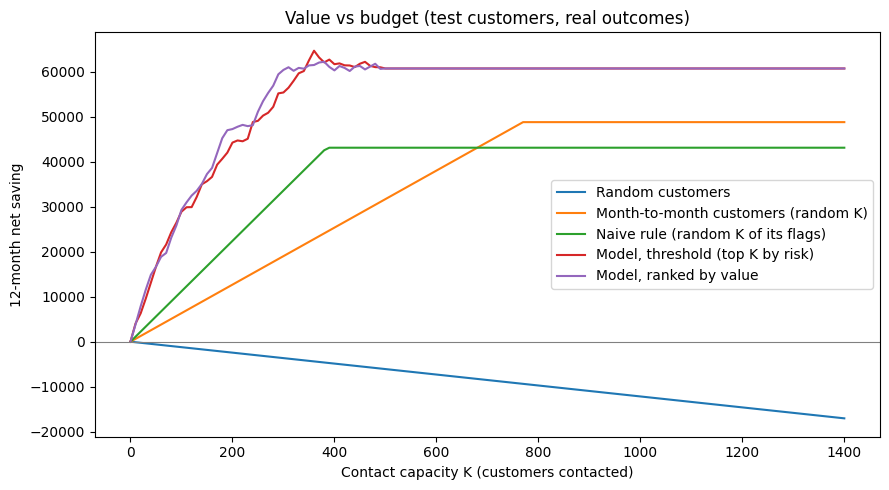

In [8]:
#baselines at the SAME budget (contact capacity K), plus value-vs-budget 
c = 0.0
rv = realized_per_customer(y, B, c=c)              # per-customer realized value
m2m = (tp.contract == "Month-to-month").to_numpy()
 
def value_at_capacity(K):
    """Value of each strategy when we can contact at most K customers."""
    K = int(K)
    in_thr = np.flatnonzero(flag_model)
    top_thr = in_thr[np.argsort(-p[in_thr])[:K]]                 # model: highest risk among those above the cutoff
    ranked = np.flatnonzero(policy_ranked(p, B, c=c, capacity=K))
    nv = flag_naive.sum(); m = m2m.sum()
    return {
        "No action": 0.0,
        "Random customers": K * rv.mean(),                                   # expected value of a random draw
        "Month-to-month customers (random K)": min(K, m) * rv[m2m].mean(),
        "Naive rule (random K of its flags)": min(K, nv) * rv[flag_naive].mean(),
        "Model, threshold (top K by risk)": rv[top_thr].sum(),
        "Model, ranked by value": rv[ranked].sum(),
    }
 
K0 = 300
print(f"At a budget of {K0} contacts:")
print(pd.Series(value_at_capacity(K0)).round(0).to_string())
 
Ks = np.arange(0, n + 1, 10)
curve = pd.DataFrame([value_at_capacity(K) for K in Ks], index=Ks)
ax = curve.drop(columns=["No action"]).plot(figsize=(9, 5))
ax.set_xlabel("Contact capacity K (customers contacted)"); ax.set_ylabel("12-month net saving")
ax.set_title("Value vs budget (test customers, real outcomes)"); ax.axhline(0, color="grey", lw=0.8)
plt.tight_layout(); plt.show()
# The model curves rise steeply, flatten, then stop (no more customers worth contacting): diminishing returns.

In [9]:
# sensitivity to the offer success rate r 
rows = []
for r_ in [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7]:
    cut_r = d / (d + r_ * (1 - d))                              # cutoff re-derived for this r
    f_adapt = p >= cut_r
    rows.append({"r": r_, "rule cutoff": round(cut_r, 2), "flagged": int(f_adapt.sum()),
                 "saving, cutoff adapted": round(realized_value(f_adapt, y, B, r=r_)),
                 "saving, cutoff kept at 0.33": round(realized_value(flag_model, y, B, r=r_))})
sens = pd.DataFrame(rows)
print(sens.to_string(index=False))
# Must match notebook 04: adapted = 2,553 / 10,439 / 28,420 / 42,581 / 60,674 / 82,395 / 104,828
assert abs(sens.loc[sens.r == 0.5, "saving, cutoff adapted"].iloc[0] - 60674) <= 1
assert abs(sens.loc[sens.r == 0.1, "saving, cutoff adapted"].iloc[0] - 2553) <= 1

  r  rule cutoff  flagged  saving, cutoff adapted  saving, cutoff kept at 0.33
0.1         0.71      106                    2553                       -21134
0.2         0.56      251                   10439                         -682
0.3         0.45      354                   28420                        19770
0.4         0.38      428                   42581                        40222
0.5         0.33      496                   60674                        60674
0.6         0.29      560                   82395                        81126
0.7         0.26      604                  104828                       101578


In [10]:
# pooled backtest on all 7,043 customers (labelled: training rows are out-of-fold)
sc = pd.read_csv("../reports/scores.csv")
raw = pd.read_csv("../data/Telco-Customer-Churn.csv")[["customerID", "Contract", "tenure"]]
raw = raw.rename(columns={"customerID": "customer_id"})
sc = sc.merge(raw, on="customer_id", how="left")
assert sc.Contract.notna().all() and len(sc) == 7043
 
y2, B2 = sc.actual_churn.to_numpy(), sc.monthly_charges.to_numpy()
rv2 = realized_per_customer(y2, B2)
fm = (sc.p_cal >= CUTOFF).to_numpy()
fn = ((sc.Contract == "Month-to-month") & (sc.tenure < 12)).to_numpy()
 
for label, mask in [("test only (headline)", (sc.score_kind == "test").to_numpy()),
                    ("out-of-fold only (slightly optimistic)", (sc.score_kind == "oof").to_numpy()),
                    ("pooled, all 7,043 (secondary view)", np.ones(len(sc), bool))]:
    nn = mask.sum()
    print(f"{label:40s} n={nn:5d}  model={rv2[fm & mask].sum():>9,.0f}  naive={rv2[fn & mask].sum():>9,.0f}  "
          f"gain per 1,000 customers={(rv2[fm & mask].sum() - rv2[fn & mask].sum()) / nn * 1000:>7,.0f}")
 
# Paired bootstrap of the gain over the naive rule (same resample for both strategies)
dv = rv2 * (fm.astype(int) - fn.astype(int))
rng = np.random.default_rng(42)
boot = np.array([dv[rng.integers(0, len(dv), len(dv))].sum() for _ in range(2000)])
lo, hi = np.percentile(boot, [2.5, 97.5])
print(f"\nPooled gain over naive rule: mean {boot.mean():,.0f}, 95% interval {lo:,.0f} to {hi:,.0f}")
print(f"As a share of the mean the interval is {(hi - lo) / 2 / boot.mean():.0%} wide on either side "
      f"(test-only interval was 8,676 to 27,360 on 1,409 customers).")

test only (headline)                     n= 1409  model=   60,674  naive=   43,079  gain per 1,000 customers= 12,488
out-of-fold only (slightly optimistic)   n= 5634  model=  251,254  naive=  164,066  gain per 1,000 customers= 15,475
pooled, all 7,043 (secondary view)       n= 7043  model=  311,928  naive=  207,145  gain per 1,000 customers= 14,878

Pooled gain over naive rule: mean 104,875, 95% interval 81,406 to 127,626
As a share of the mean the interval is 22% wide on either side (test-only interval was 8,676 to 27,360 on 1,409 customers).


In [11]:
# Revenue numbers for the Business Overview page. Two DIFFERENT figures, always labelled separately.
 
# the two revenue definitions
import json
 
raw = pd.read_csv("../data/Telco-Customer-Churn.csv")
raw = raw.rename(columns={"customerID": "customer_id", "MonthlyCharges": "monthly_charges"})
raw["churned"] = (raw.Churn == "Yes").astype(int)
 
# scores.csv has an honest probability for every customer (out-of-fold for train, test for test)
sc = pd.read_csv("../reports/scores.csv")[["customer_id", "p_cal", "score_kind"]]
df = raw.merge(sc, on="customer_id", how="left")
assert len(df) == 7043 and df.p_cal.notna().all()
 
total_rev = df.monthly_charges.sum()
 
# (a) Revenue ALREADY LOST: customers flagged churned in the data have left
lost = df.loc[df.churned == 1, "monthly_charges"].sum()
 
# (b) Expected revenue AT RISK among customers who are still here (probability x monthly bill)
current = df[df.churned == 0]
at_risk = (current.p_cal * current.monthly_charges).sum()
 
print(f"Total monthly revenue (all 7,043 customers)   : {total_rev:>10,.0f}")
print(f"(a) Monthly revenue already lost              : {lost:>10,.0f}  ({lost / total_rev:.1%} of total)")
print(f"    current customers: {len(current):,}, their monthly revenue {current.monthly_charges.sum():,.0f}")
print(f"(b) Expected monthly revenue at risk (current): {at_risk:>10,.0f}  "
      f"({at_risk / current.monthly_charges.sum():.1%} of current revenue)")
# Caveat for the app: (b) applies the model's churn probability to customers who did NOT leave in
# this snapshot, i.e. it assumes the same churn process continues over the next period.

Total monthly revenue (all 7,043 customers)   :    456,117
(a) Monthly revenue already lost              :    139,131  (30.5% of total)
    current customers: 5,174, their monthly revenue 316,986
(b) Expected monthly revenue at risk (current):     67,610  (21.3% of current revenue)


In [12]:
# segments (minimum size 100, ranked by revenue lost, not only churn rate) 
df["tenure_band"] = pd.cut(df.tenure, [-1, 11, 35, 72], labels=["0-11", "12-35", "36-72"]).astype(str)
df["risk_x_bill"] = df.p_cal * df.monthly_charges
df["lost_rev"] = df.monthly_charges * df.churned
df["current_rev_at_risk"] = np.where(df.churned == 0, df.risk_x_bill, 0.0)
 
def segment_table(col, min_n=100):
    g = df.groupby(col).agg(customers=("customer_id", "size"), churned=("churned", "sum"),
                            revenue_lost=("lost_rev", "sum"), expected_at_risk=("current_rev_at_risk", "sum"))
    g["churn_rate"] = g.churned / g.customers
    g["share_of_lost"] = g.revenue_lost / lost
    g = g[g.customers >= min_n].sort_values("revenue_lost", ascending=False)
    g.insert(0, "dimension", col)
    return g.reset_index().rename(columns={col: "segment"})
 
dims = {"Contract": "contract", "InternetService": "internet_service",
        "PaymentMethod": "payment_method", "tenure_band": "tenure_band"}
seg_rev = pd.concat([segment_table(c).assign(dimension=name) for c, name in dims.items()], ignore_index=True)
print(seg_rev.round({"revenue_lost": 0, "expected_at_risk": 0, "churn_rate": 3, "share_of_lost": 3}).to_string(index=False))

                  segment        dimension  customers  churned  revenue_lost  expected_at_risk  churn_rate  share_of_lost
           Month-to-month         contract       3875     1655      120847.0           52992.0       0.427          0.869
                 One year         contract       1473      166       14118.0           11068.0       0.113          0.101
                 Two year         contract       1695       48        4165.0            3550.0       0.028          0.030
              Fiber optic internet_service       3096     1297      114300.0           50614.0       0.419          0.822
                      DSL internet_service       2421      459       22529.0           15110.0       0.190          0.162
                       No internet_service       1526      113        2302.0            1887.0       0.074          0.017
         Electronic check   payment_method       2365     1071       84289.0           35346.0       0.453          0.606
Bank transfer (automatic

In [13]:
# export for the dashboard 
overview = {
    "n_customers": int(len(df)),
    "total_monthly_revenue": round(float(total_rev), 2),
    "revenue_lost_monthly": round(float(lost), 2),
    "revenue_lost_share": round(float(lost / total_rev), 4),
    "n_current_customers": int(len(current)),
    "current_monthly_revenue": round(float(current.monthly_charges.sum()), 2),
    "expected_revenue_at_risk_monthly": round(float(at_risk), 2),
    "definitions": {
        "revenue_lost": "Sum of monthly charges of customers marked churned in the data (already left).",
        "expected_at_risk": "Sum of calibrated churn probability x monthly charge over customers still active. "
                            "Uses out-of-fold scores for training rows. Assumes the churn process continues.",
    },
}
json.dump(overview, open("../reports/overview_numbers.json", "w"), indent=2)
seg_rev.to_csv("../reports/segment_revenue.csv", index=False)
print("saved overview_numbers.json and segment_revenue.csv")

saved overview_numbers.json and segment_revenue.csv


## Summary and hand-off to the app

**Findings (all with r = 0.5, d = 20%, M = 12; savings in the data's currency units)**

1. **Self-test passed.** The economics functions reproduce notebook 04 exactly: 60,674 realized and
   67,009 expected at the 0.333 cutoff, 496 customers flagged.
2. **Contact cost changes the best policy.** At zero cost the cutoff rule and the ranked-by-value
   policy are identical. As the cost per contact grows, ranking by expected value flags fewer
   customers and loses less (at c = 40: 45,681 vs 40,834). At low costs the held-out difference is
   within noise, so the app shows the expected and held-out views side by side.
3. **A small, well-chosen budget captures almost everything.** With 300 contacts, ranking by value earns
   60,354, which is 99.5% of the full result with 60% of the contacts. Random contacts lose money (−3,648).
   The curve's peak on the test set is not a budget recommendation: choosing the best-looking point on one
   test set would overfit it.
4. **The offer success rate matters.** With the cutoff re-derived for each r, the saving ranges from 2,553
   (r = 0.1) to 104,828 (r = 0.7). Keeping the 0.333 cutoff when r is really low loses money
   (−21,134 at r = 0.1).
5. **The gain over the naive rule holds across views**, per 1,000 customers: 12,488 (test only, the
   headline), 15,475 (out-of-fold) and 14,878 (pooled, 95% interval about 11,560 to 18,120). Out-of-fold
   results are slightly optimistic because hyperparameters were tuned on those folds.
6. **Revenue.** 139,131 a month (30.5% of 456,117) is already lost. Expected revenue at risk among current
   customers is 67,610 a month (21.3% of their revenue). Month-to-month customers hold 86.9% of lost
   revenue; customers with tenure under 12 months churn at 48.3%.

**Caveats**
- r, d and M are assumptions; the data has no offers. The model predicts churn, not response to an offer.
- Expected revenue at risk assumes the same churn process continues. It is not a forecast.
- Segment shares add to 100% within each dimension, not across dimensions.
- Segments describe where revenue was lost, not why.

**What feeds the app**
- The functions in cells 2 and 3 move to `churn_core/economics.py`; the self-test becomes a unit test.
- `reports/scores.csv` and `reports/test_predictions.csv` drive the Simulator and its backtest toggle.
- `reports/overview_numbers.json` and `reports/segment_revenue.csv` drive the Business Overview page.